# Method comparison
All methods, scored the same way: reconstruct a player's full-season (900+ minute) per-90 volume profile from their first matches, then rebuild every rate from the estimated volumes.

Setup: Fall regular-season player-seasons with at least 900 minutes, grouped by most-played position group; female and male separately; 5-fold GroupKFold by player. Every per-game prefix (up to 750 minutes) is a training/test row; scores are reported in three minutes bins and each player-season counts once per bin.

**Final model: the ridge regression** (`ridge`) with minutes-conditional z-scored inputs. `ridge_kalman` is its best variant.

In [1]:
%matplotlib inline
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
# make the repo root importable no matter which folder the notebook is opened from
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "low_minute_player_analysis").is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from low_minute_player_analysis import notebook_helpers as nh
from low_minute_player_analysis import reconstruct_methods as rm
from low_minute_player_analysis import temporal_methods as tm
from low_minute_player_analysis import reconstruction_eval as ev

nh.apply_style()
r = nh.load_results("results")         # out-of-fold scores for every group, gender and method
V, R = nh.volume(r), nh.rates(r)       # volume stats / rates rebuilt from the estimated volumes
P = nh.load_paired("results")          # paired differences vs the final ridge, with bootstrap intervals
nh.describe(r)

79,101 scored rows | genders ['female', 'male'] | 7 groups | checkpoints [np.int64(250), np.int64(500), np.int64(750)] | methods ['raw', 'shrink', 'ridge', 'knn', 'ot_1d', 'ot_joint', 'ot_group', 'kalman', 'kalman_blend', 'ridge_kalman', 'gru']
volume stats scored: 113 | rebuilt rates scored: 74


**Re-running the evaluation (optional).** The scores above come from `results/results.parquet`. Set `RUN_EVALUATION = True` to recompute them for all 14 gender/position-group sets and 11 methods (takes hours; needs `results/truth_*.parquet` and `prefixes_*.parquet` from notebook 00 and the database).

In [2]:
RUN_EVALUATION = False
if RUN_EVALUATION:
    ev.run_evaluation(n_jobs=8, tag="results")
    r = nh.load_results("results")
    V, R = nh.volume(r), nh.rates(r)
    P = nh.load_paired("results")
    nh.describe(r)

**How to read the numbers.** `nrmse` is the RMSE of the estimate against the player's true full-season
per-90, divided by the standard deviation of that true value. 0 is perfect; 1 means no better than guessing
the group average. Every table shows the **median over stats** (and over groups/genders unless stated).
The three columns / x positions are **minutes bins** of the sample the estimate was made from: 250 = 0-375 minutes,
500 = 375-625, 750 = 625-750 (every per-game prefix of a held-out player is scored; each player-season counts once
per bin). Scores are out-of-fold: the 5 folds split players, so nobody is predicted by a model that saw them.

## 1. Volume stats

method,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
checkpoint,,,,,,,,,,,
250,1.489,0.817,0.769,0.864,0.899,0.861,0.837,0.813,0.799,0.764,0.773
500,0.713,0.618,0.552,0.758,0.611,0.735,0.629,0.608,0.580,0.552,0.588
750,0.518,0.524,0.457,0.714,0.480,0.678,0.535,0.507,0.464,0.455,0.511


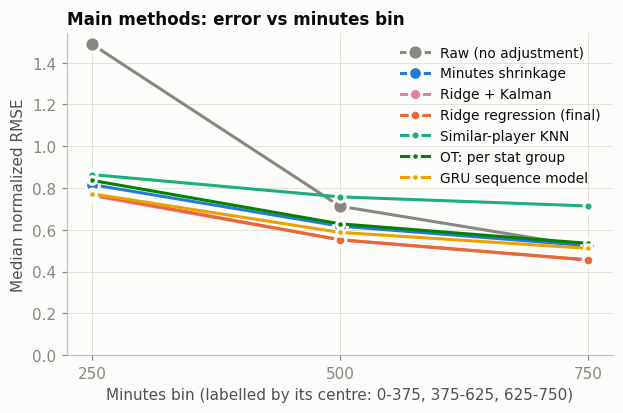

In [3]:
ORDER = [m for m in nh.METHOD_ORDER if m in set(r.method)]
summary = nh.median_nrmse(V, ORDER)
display(summary.round(3))
CURVE = [m for m in nh.CURVE_METHODS if m in ORDER]
nh.curve_plot(summary, CURVE, "Main methods: error vs minutes bin")
plt.show()

In [4]:
print("Median % error reduction vs raw")
display(nh.improvement_table(V, ORDER[1:]).mul(100).round(1))
print("Share of (gender, group, bin, stat) cases where each method has the lowest error")
display(nh.best_method_share(V, ORDER).mul(100).round(1))

Median % error reduction vs raw


method,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
checkpoint,,,,,,,,,,
250,45.1,48.1,42.7,40.1,42.3,44.1,45.5,46.5,48.2,48.2
500,12.0,21.6,-3.2,13.9,-1.4,12.4,13.4,17.6,21.7,17.3
750,0.0,11.2,-30.5,7.5,-26.5,-0.0,1.7,10.3,12.1,2.8


Share of (gender, group, bin, stat) cases where each method has the lowest error


method,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
checkpoint,,,,,,,,,,,
250,1.0,0.4,8.1,0.0,0.4,0.1,0.4,0.6,17.3,65.1,6.6
500,0.8,0.7,19.9,0.0,0.9,0.0,0.2,0.5,14.6,62.3,0.1
750,0.8,0.2,4.9,0.1,2.5,0.0,0.2,0.8,37.0,53.5,0.0


### Is the ridge really better? Paired test against the final ridge
For each player-season, the squared error (divided by the bin's truth variance, averaged over stats) of the method minus that of the ridge; negative = better than the ridge. The mean is over the 14 gender-group sets; `better` / `worse` count the sets where the 95% bootstrap interval is entirely below / above 0.

In [5]:
display(nh.paired_summary(P, [m for m in ORDER if m != "ridge"]).round(4))

mean_diff  better  worse  sets
method       checkpoint                                
raw          250            3.2347       0     14    14
             500            0.3320       0     14    14
             750            0.0950       0     13    14
shrink       250            0.0882       0     12    14
             500            0.1258       0     14    14
             750            0.1153       0     13    14
knn          250            0.0949       0     11    14
             500            0.2318       0     14    14
             750            0.2514       0     13    14
ot_1d        250            0.1542       0     11    14
             500            0.0694       0     14    14
             750            0.0099       0     13    14
ot_joint     250            0.0946       0     11    14
             500            0.1984       0     14    14
             750            0.2044       0     13    14
ot_group     250            0.0447       0     11    14
             500            0.0704       0     14    14
             750            0.0448       0     13    14
kalman       250            0.1496       0     11    14
             500            0.3137       0     14    14
             750            0.1037       0     13    14
kalman_blend 250            0.0832       0     11    14
             500            0.1128       0     13    14
             750           -0.0194       3      7    14
ridge_kalman 250           -0.0252      13      0    14
             500           -0.0011       8      1    14
             750           -0.0147       9      0    14
gru          250            0.5507       0      8    14
             500            0.5451       0     14    14
             750            0.5884       0     14    14

### By position group (500 bin)

method,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
group,,,,,,,,,,,
Attacking Midfielders,0.631,0.562,0.521,0.747,0.563,0.703,0.589,0.562,0.540,0.520,0.554
Center Backs,0.770,0.638,0.579,0.774,0.648,0.759,0.652,0.627,0.611,0.579,0.604
Center Forwards,0.646,0.569,0.519,0.733,0.566,0.700,0.598,0.560,0.539,0.519,0.548
Central Midfielders,0.647,0.576,0.520,0.712,0.574,0.702,0.587,0.572,0.553,0.519,0.545
GK,1.141,0.902,0.756,0.881,0.819,0.860,0.796,0.867,0.752,0.757,0.802
Outside Backs,0.689,0.603,0.550,0.732,0.599,0.708,0.617,0.598,0.577,0.548,0.576
Wingers,0.635,0.571,0.524,0.767,0.556,0.744,0.607,0.557,0.531,0.522,0.579


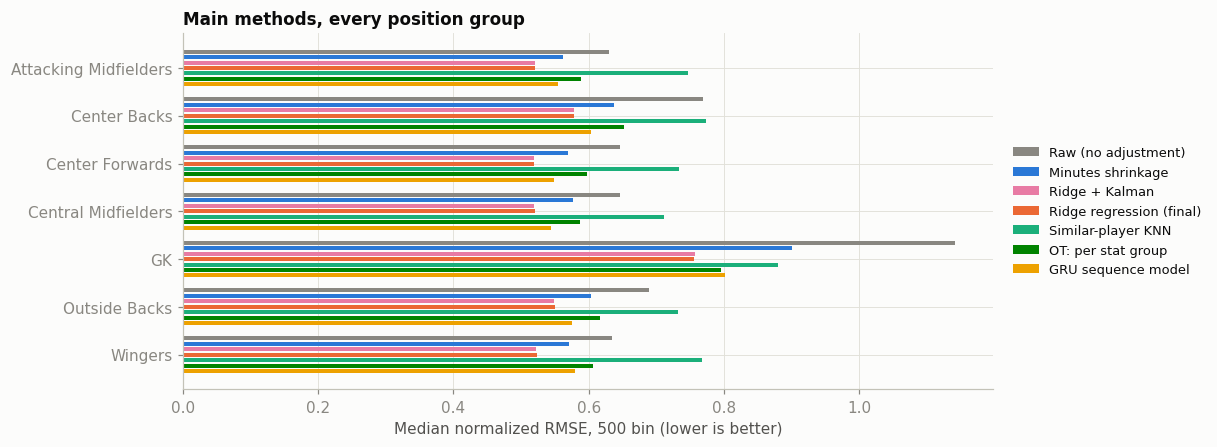

In [6]:
g = V[V.checkpoint == 500].groupby(["group", "method"])["nrmse"].median().unstack()[ORDER]
display(g.round(3))
fig, ax = plt.subplots(figsize=(9.5, 4.2))
h = 0.8 / len(CURVE)
for i, m in enumerate(CURVE):
    ax.barh(np.arange(len(g)) + (i - len(CURVE) / 2 + 0.5) * h, g[m], height=h - 0.03, color=nh.COLORS[m], label=nh.LABELS[m])
ax.set_yticks(np.arange(len(g)), g.index); ax.invert_yaxis()
ax.set_xlabel("Median normalized RMSE, 500 bin (lower is better)")
ax.set_title("Main methods, every position group", loc="left"); ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=8.5); plt.show()

### Female vs male

In [7]:
display(V.groupby(["gender", "checkpoint", "method"])["nrmse"].median().unstack()[ORDER].round(3))

method               raw  shrink  ridge    knn  ot_1d  ot_joint  ot_group  \
gender checkpoint                                                           
female 250         1.474   0.812  0.763  0.858  0.891     0.855     0.833   
       500         0.707   0.609  0.547  0.752  0.605     0.736     0.621   
       750         0.511   0.510  0.449  0.707  0.471     0.675     0.527   
male   250         1.524   0.825  0.783  0.870  0.907     0.867     0.840   
       500         0.724   0.626  0.561  0.765  0.617     0.734     0.636   
       750         0.531   0.531  0.469  0.722  0.488     0.681     0.546   

method             kalman  kalman_blend  ridge_kalman    gru  
gender checkpoint                                             
female 250          0.805         0.794         0.758  0.769  
       500          0.600         0.577         0.546  0.578  
       750          0.496         0.458         0.446  0.499  
male   250          0.818         0.803         0.781  0.779  
       500          0.616         0.587         0.561  0.596  
       750          0.518         0.473         0.468  0.523

## 2. Which volume stats are predicted well, and which are not?
One row per stat. Values are the **median normalized RMSE over the 14 gender/position-group sets** (a stat that only exists for goalkeepers is a median over the 2 GK sets). Change `CP` to look at the 250 or 750 bin. The lowest value in each row is the best method for that stat.

In [8]:
from low_minute_player_analysis import stat_groups as sg
CP = 500
tbl = nh.stat_table(V, ORDER, CP)
best = nh.best_per_stat(tbl)
print(f"Best predicted stats in the {CP} bin (lowest error of any method)")
display(best.head(15).round(3))
print(f"Worst predicted stats in the {CP} bin")
display(best.tail(15).iloc[::-1].round(3))
print("How often each method is the best for a stat:", best["best_method"].value_counts().to_dict())

Best predicted stats in the 500 bin (lowest error of any method)


,best_nrmse,best_method
stat,,
offensive_duels,0.391,ridge_kalman
dribbles,0.401,ridge_kalman
corners,0.402,ridge_kalman
successful_passes,0.408,ridge_kalman
duels,0.408,ridge_kalman
offensive_duels_won,0.419,ridge_kalman
attacking_actions,0.422,ridge_kalman
passes,0.425,ridge_kalman
received_pass,0.428,ridge


Worst predicted stats in the 500 bin


,best_nrmse,best_method
stat,,
red_cards,0.797,kalman_blend
goals_prevented,0.794,kalman_blend
direct_red_cards,0.787,kalman_blend
xa_minus_assists,0.777,kalman_blend
third_assists,0.770,kalman_blend
goals_minus_xg,0.769,kalman_blend
gk_clean_sheets,0.760,ridge
second_assists,0.757,ridge
gk_aerial_duels_won,0.726,ridge


How often each method is the best for a stat: {'ridge_kalman': 77, 'ridge': 28, 'kalman_blend': 8}


### Every stat, every method (sorted from best to worst predicted)

In [9]:
pd.set_option("display.max_rows", 200)
display(tbl.loc[best.index].round(3))

method,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
stat,,,,,,,,,,,
offensive_duels,0.421,0.399,0.392,0.600,0.404,0.582,0.460,0.399,0.396,0.391,0.425
dribbles,0.451,0.421,0.402,0.562,0.426,0.545,0.442,0.417,0.416,0.401,0.427
corners,0.444,0.416,0.410,0.783,0.417,0.733,0.591,0.420,0.411,0.402,0.468
successful_passes,0.475,0.427,0.409,0.585,0.427,0.571,0.486,0.425,0.433,0.408,0.436
duels,0.440,0.422,0.409,0.584,0.422,0.563,0.466,0.420,0.415,0.408,0.431
offensive_duels_won,0.470,0.436,0.420,0.592,0.442,0.572,0.460,0.437,0.429,0.419,0.456
attacking_actions,0.468,0.434,0.423,0.575,0.438,0.542,0.514,0.433,0.430,0.422,0.453
passes,0.490,0.440,0.427,0.591,0.443,0.565,0.506,0.437,0.445,0.425,0.459
received_pass,0.492,0.440,0.428,0.616,0.437,0.607,0.509,0.441,0.447,0.429,0.476


### The same, as heatmaps by stat group
Darker = larger error; bold = the best method for that stat.

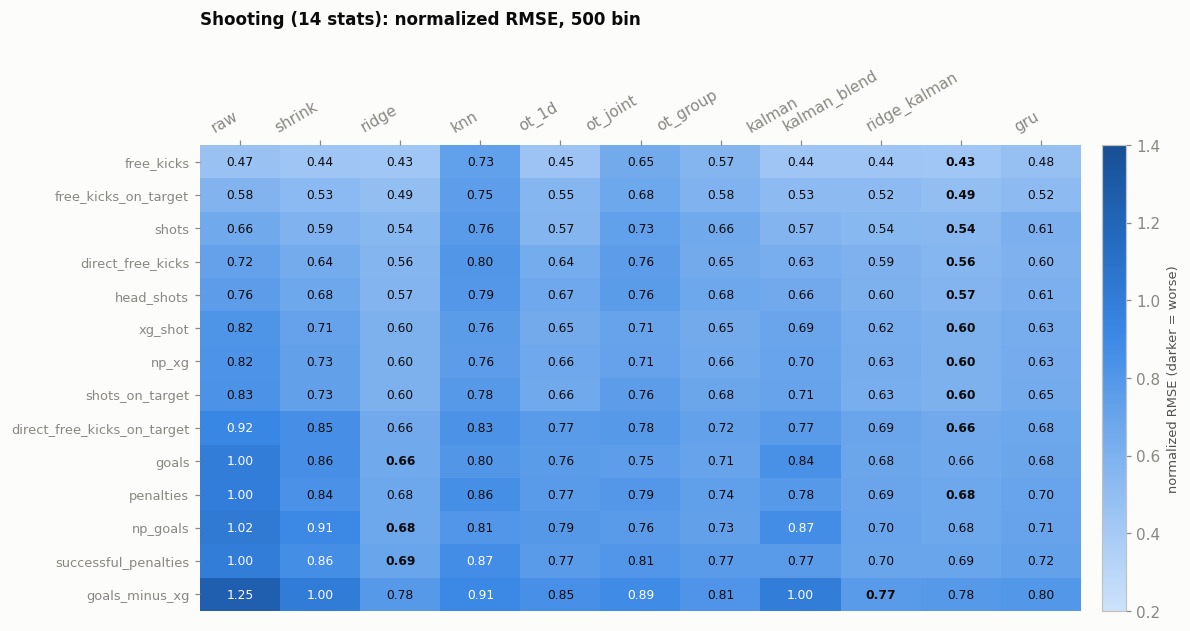

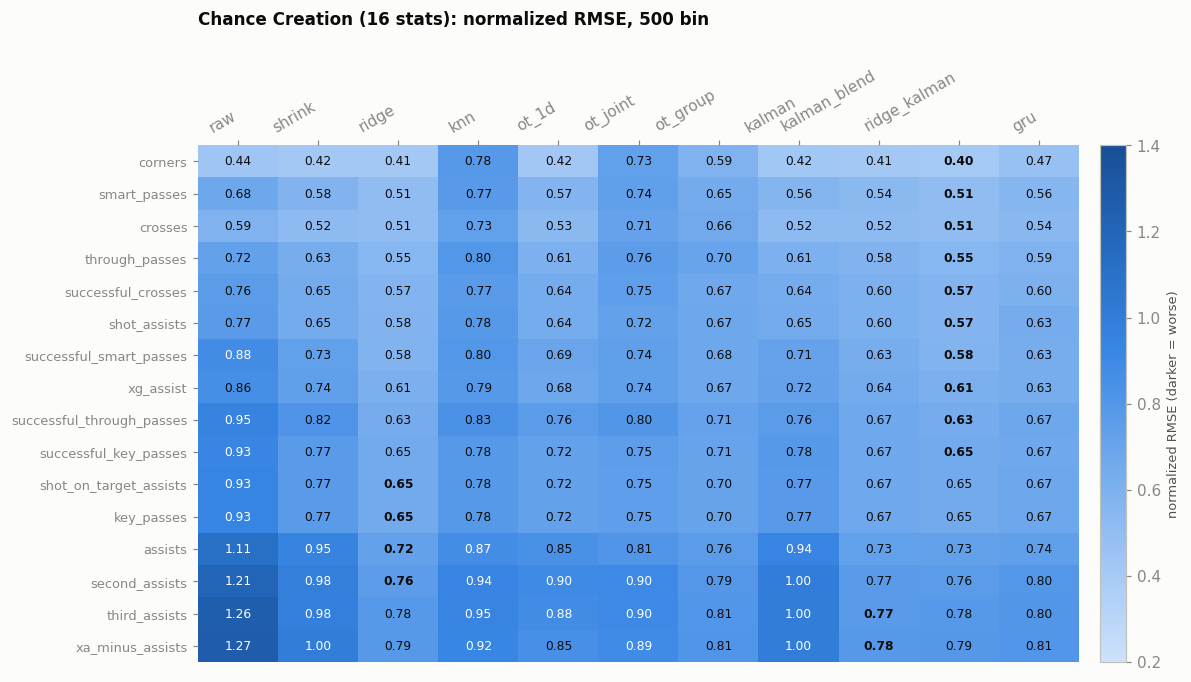

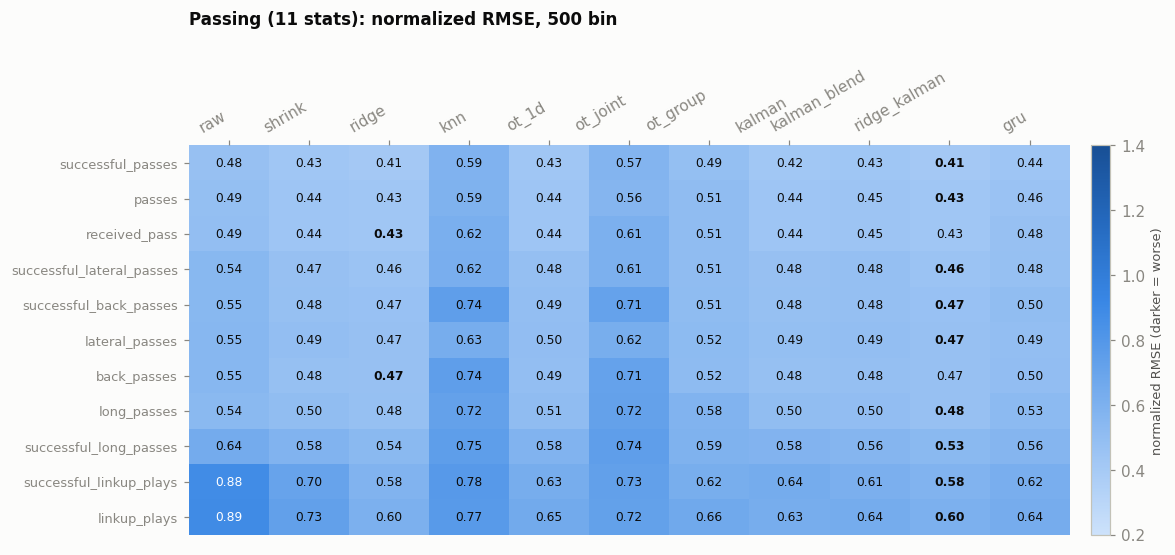

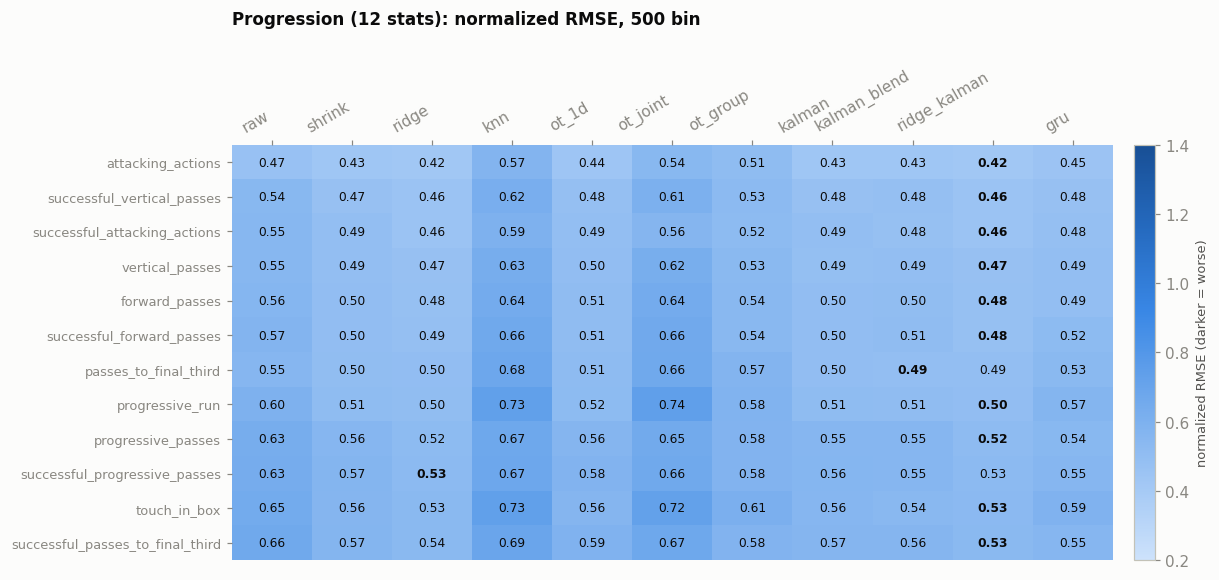

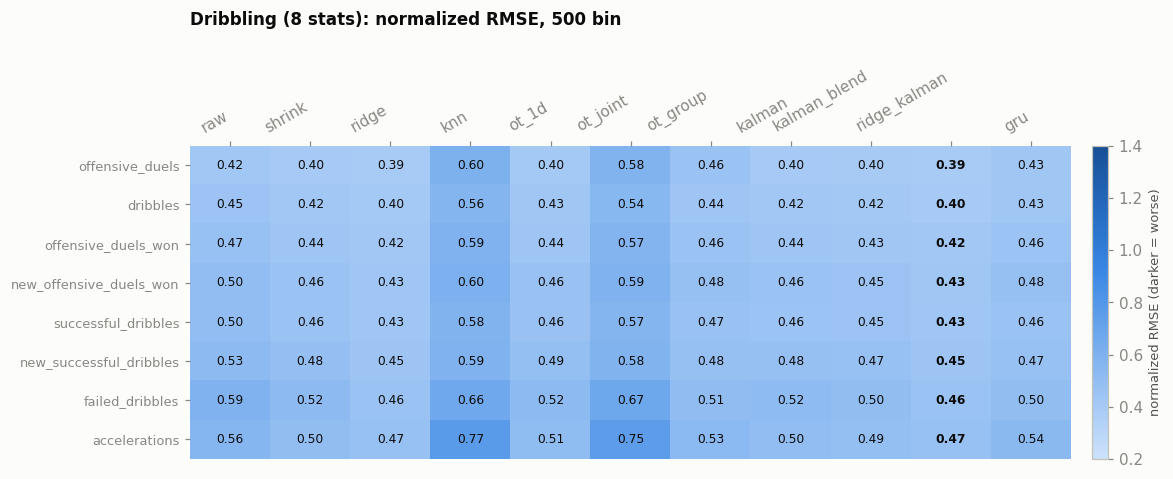

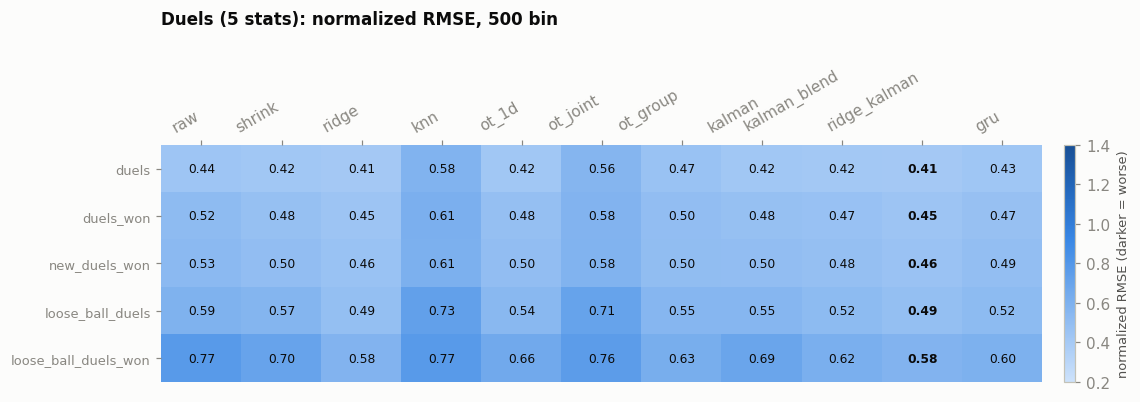

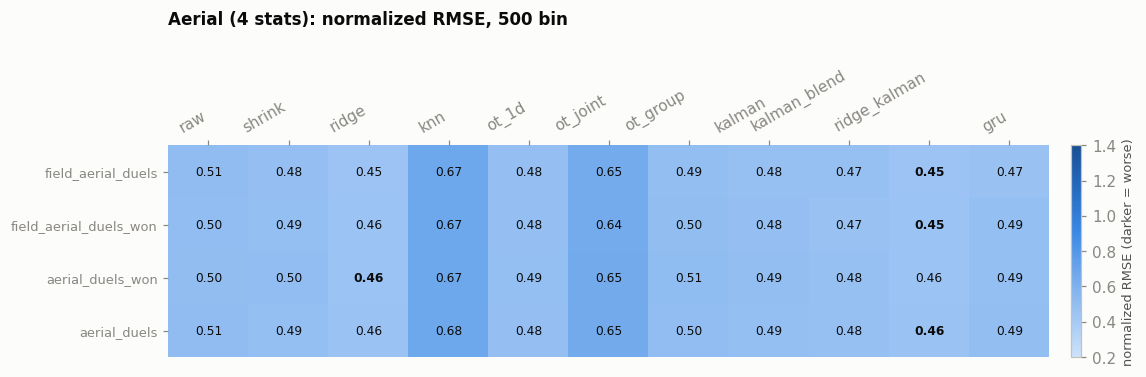

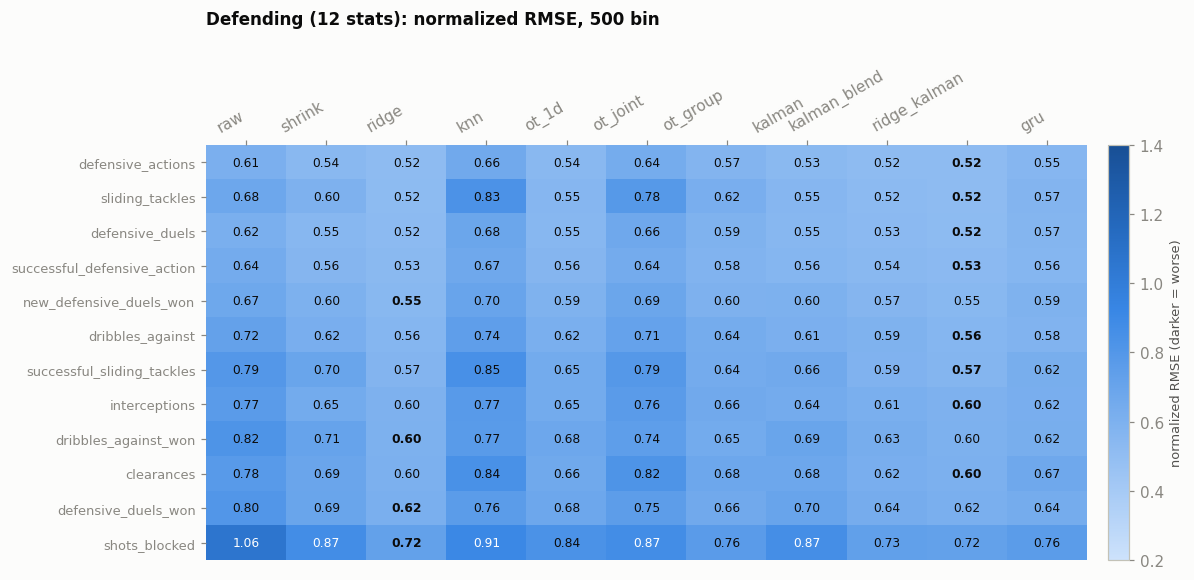

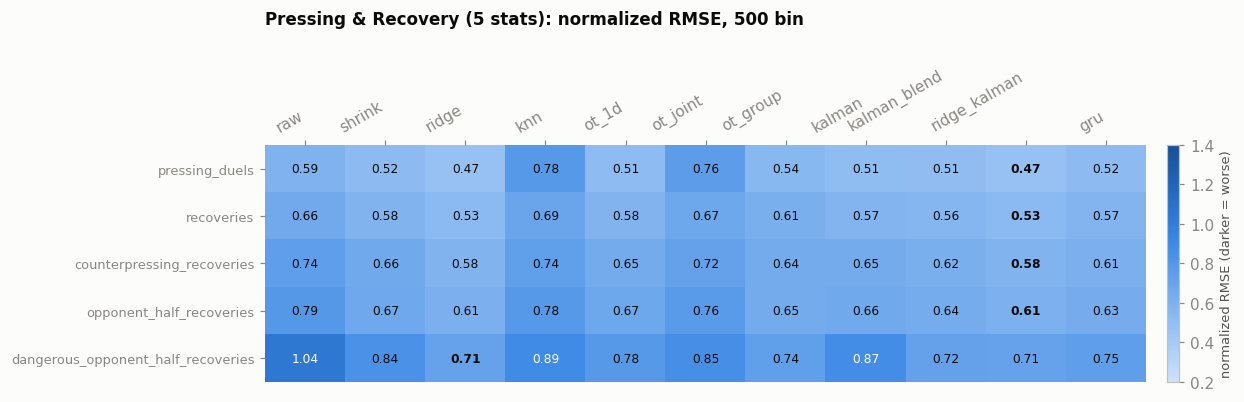

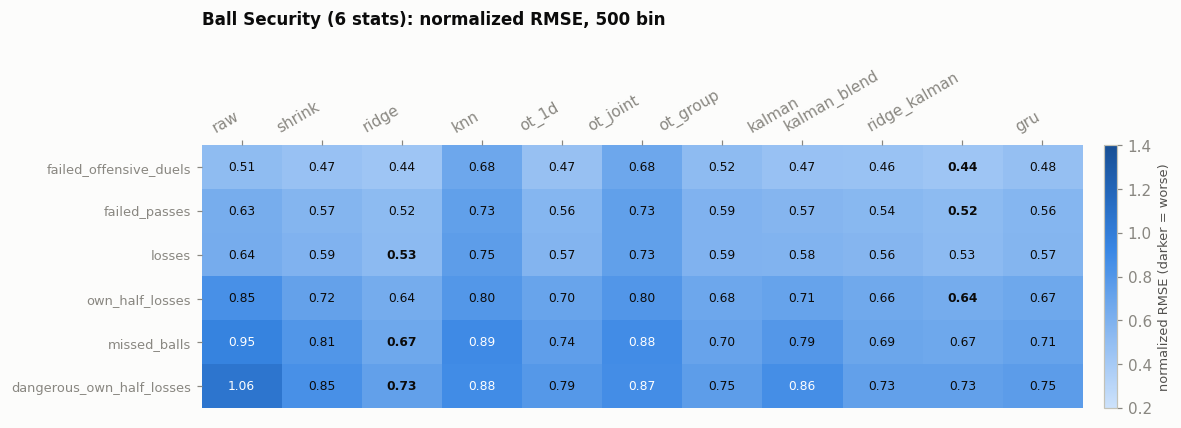

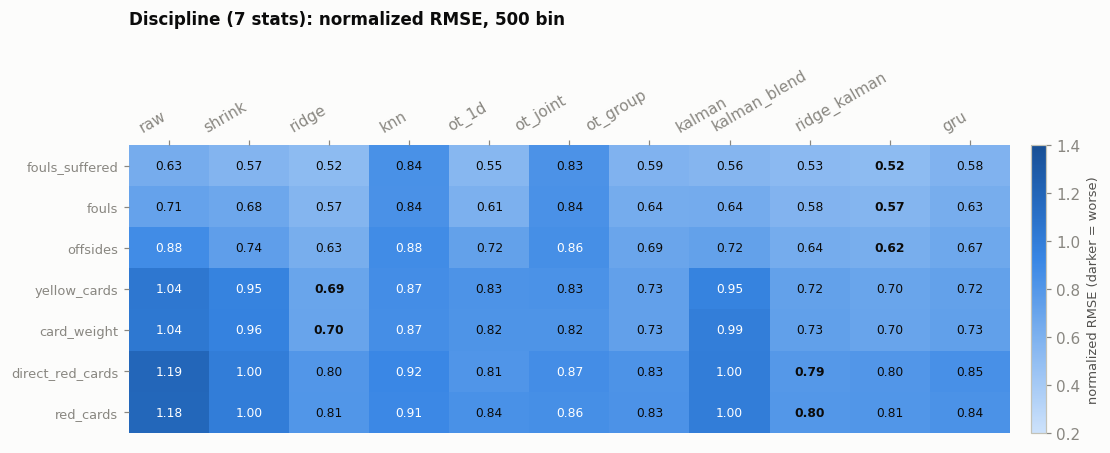

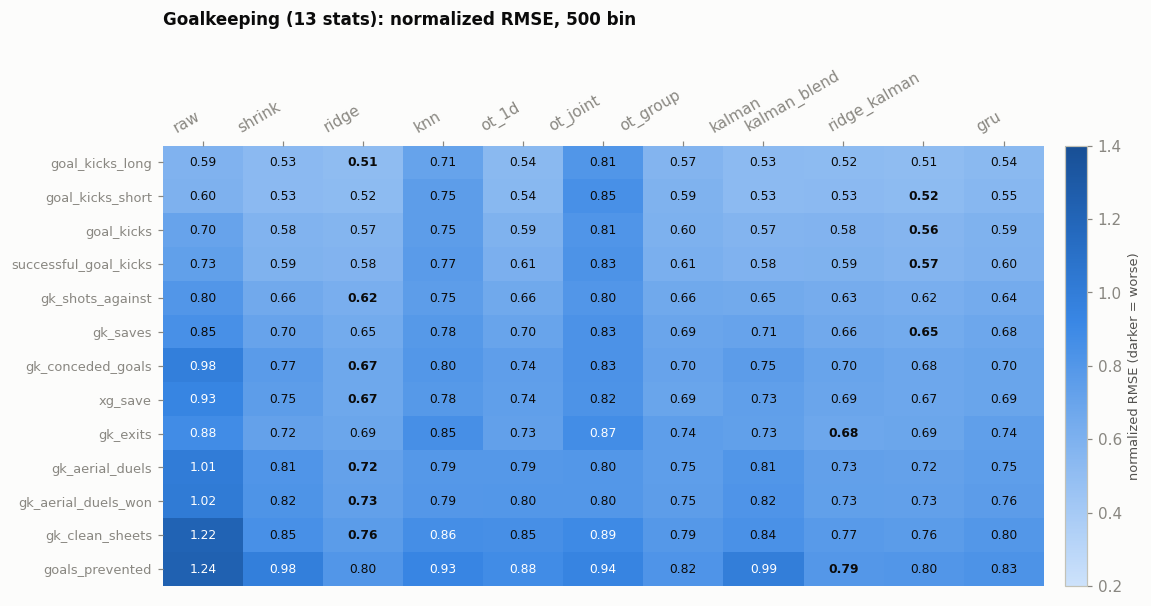

In [10]:
groups, _ = sg.stat_to_groups(list(tbl.index))
for g, stems in groups.items():
    stems = [s for s in stems if s in tbl.index]
    nh.heatmap(tbl.loc[stems], f"{g} ({len(stems)} stats): normalized RMSE, {CP} bin")
    plt.show()

### Does a stat get easier as minutes grow?
Lowest error of any method for each stat, in each minutes bin (sorted by the 500-bin value).

In [11]:
by_cp = pd.concat({cp: nh.best_per_stat(nh.stat_table(V, ORDER, cp))["best_nrmse"] for cp in (250, 500, 750)}, axis=1)
by_cp.columns = [f"{c} bin" for c in by_cp.columns]
display(by_cp.sort_values("500 bin").round(3))

,250 bin,500 bin,750 bin
stat,,,
offensive_duels,0.629,0.391,0.292
dribbles,0.620,0.401,0.315
corners,0.618,0.402,0.311
successful_passes,0.633,0.408,0.319
duels,0.653,0.408,0.313
offensive_duels_won,0.656,0.419,0.323
attacking_actions,0.643,0.422,0.328
passes,0.651,0.425,0.332
received_pass,0.654,0.428,0.331


### RMSE in the stat's own units for one group
Normalized RMSE is comparable across stats; raw RMSE is what you would quote for one stat (per 90 minutes, or percentage points for percents). Pick a gender and group below. `truth_sd` is how much the true full-season value varies between players, so an RMSE well below it means the stat is predicted well.

In [12]:
GENDER, GROUP = "female", "Center Forwards"
units = nh.stat_rmse_units(V, ORDER, 500, GROUP, GENDER)
display(units.sort_values("truth_sd", ascending=False).round(3))

method,truth_sd,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
stat,,,,,,,,,,,,
duels,6.249,2.624,2.571,2.480,3.703,2.527,3.539,2.770,2.553,2.509,2.479,2.614
passes,5.776,2.726,2.530,2.450,3.439,2.546,3.260,2.952,2.487,2.524,2.434,2.606
successful_passes,4.731,2.132,1.973,1.915,2.874,2.010,2.728,2.333,1.945,1.973,1.905,2.055
offensive_duels,4.578,1.995,1.933,1.886,2.800,1.931,2.732,2.126,1.935,1.909,1.881,2.002
received_pass,3.904,2.014,1.800,1.755,2.581,1.838,2.495,2.061,1.782,1.812,1.750,1.944
attacking_actions,3.677,1.798,1.660,1.581,2.079,1.689,1.982,1.916,1.649,1.646,1.575,1.664
failed_offensive_duels,2.804,1.439,1.377,1.274,1.937,1.372,1.909,1.456,1.363,1.345,1.272,1.354
losses,2.762,1.627,1.531,1.360,2.004,1.466,1.951,1.519,1.513,1.476,1.356,1.453
new_duels_won,2.727,1.357,1.290,1.196,1.634,1.284,1.559,1.286,1.290,1.247,1.194,1.251


## 3. Rates rebuilt from the estimated volumes

In [13]:
display(nh.median_nrmse(R, ORDER).round(3).rename_axis("minutes bin"))
print("Median nrmse by rate type, 500 bin")
display(nh.rate_table(R, ORDER, cp=500).round(3))
print("Rates the truth has but the estimate could not produce")
display(nh.missing_table(R, ORDER).round(4))

method,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
minutes bin,,,,,,,,,,,
250,1.737,0.911,0.857,0.933,1.015,0.938,0.911,0.903,0.901,0.843,0.877
500,0.838,0.721,0.654,0.875,0.719,0.874,0.765,0.718,0.707,0.650,0.730
750,0.610,0.606,0.564,0.847,0.566,0.840,0.689,0.612,0.569,0.560,0.667


Median nrmse by rate type, 500 bin


method,raw,shrink,ridge,knn,ot_1d,ot_joint,ot_group,kalman,kalman_blend,ridge_kalman,gru
stat_type,,,,,,,,,,,
rate_api_approx,0.844,0.681,0.642,0.848,0.766,0.870,0.798,0.691,0.718,0.631,0.790
rate_api_exact,1.031,0.875,0.820,0.964,0.906,0.980,0.902,0.879,0.838,0.819,0.965
rate_derived,0.754,0.637,0.573,0.807,0.638,0.797,0.680,0.633,0.606,0.571,0.620


Rates the truth has but the estimate could not produce


,n_truth_ok,n_est_missing,n_compared,est_missing_share
method,,,,
raw,17532604,1039980,16492624,0.0593
shrink,17532604,139671,17392933,0.0080
ridge,17532604,162703,17369901,0.0093
knn,17532604,205591,17327013,0.0117
ot_1d,17532604,329083,17203521,0.0188
ot_joint,17532604,166812,17365792,0.0095
ot_group,17532604,160012,17372592,0.0091
kalman,17532604,140005,17392599,0.0080
kalman_blend,17532604,152685,17379919,0.0087


### Every rebuilt rate: which are predicted well?
Median normalized RMSE over the position-group sets, only where the truth and the estimate both exist. `api_exact` / `api_approx` are the API percentages (success rates), `derived` are the engineered shares and ratios.

Best predicted rates, 500 bin


,best_nrmse,best_method
stat,,
percent_take_on_rate,0.386,ridge_kalman
percent_offensive_duel_share,0.420,ridge_kalman
percent_loss_rate_per_touch,0.440,ridge_kalman
percent_aerial_duel_share,0.446,ridge_kalman
percent_penalties_conversion,0.450,raw
percent_retention_rate,0.457,ridge
percent_loss_rate,0.457,ridge
percent_successful_passes,0.457,ridge_kalman
percent_directness_index,0.461,ridge_kalman


Worst predicted rates, 500 bin


,best_nrmse,best_method
stat,,
percent_successful_key_passes,0.861,kalman_blend
percent_successful_crosses,0.853,ridge_kalman
percent_successful_through_passes,0.850,kalman_blend
percent_new_successful_dribbles,0.845,ridge
percent_gk_aerial_duels_won,0.841,kalman_blend
percent_successful_dribbles,0.818,kalman_blend
percent_gk_saves,0.818,ridge_kalman
percent_dribbles_against_won,0.818,ridge_kalman
percent_goal_conversion,0.807,ridge


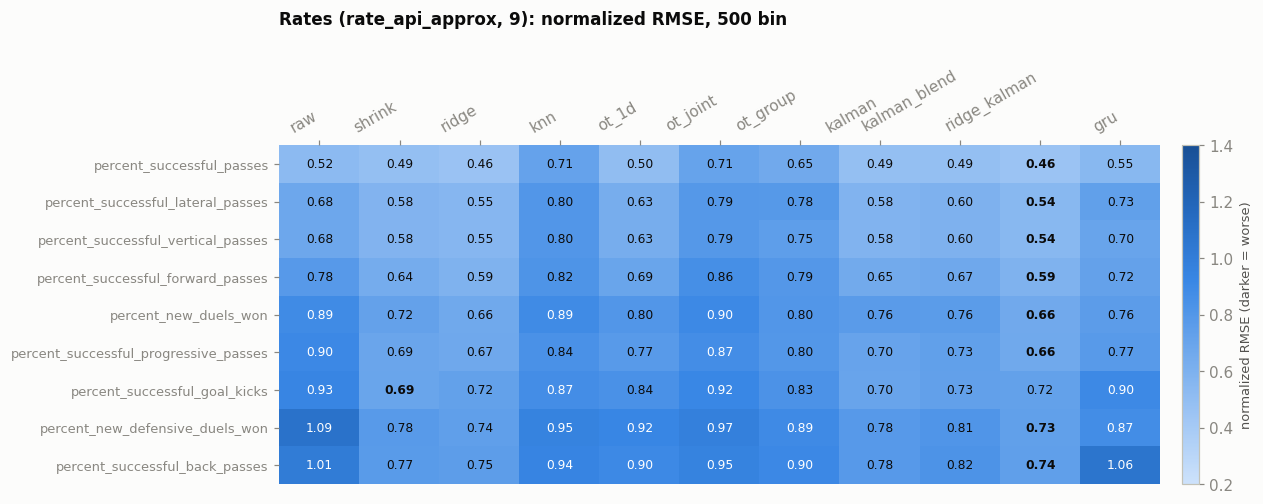

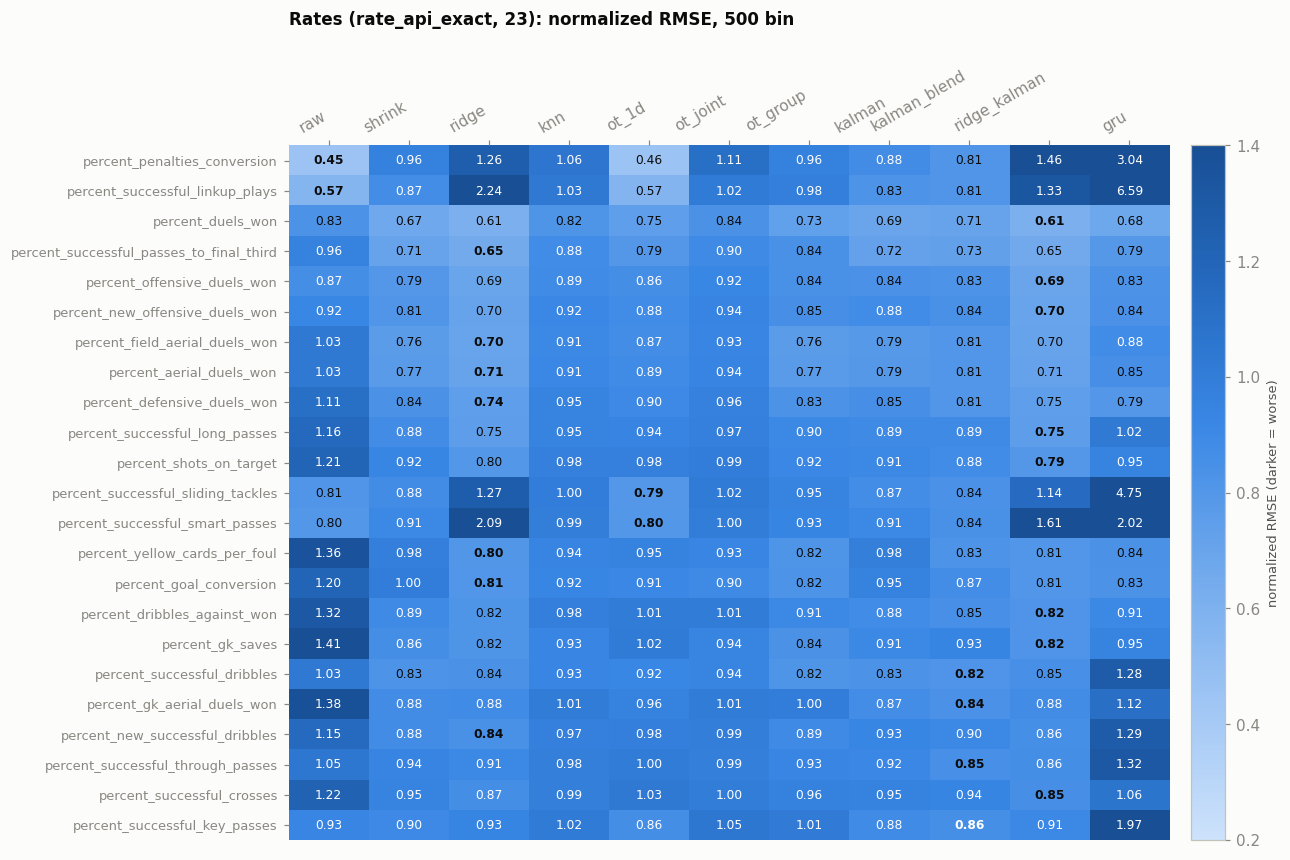

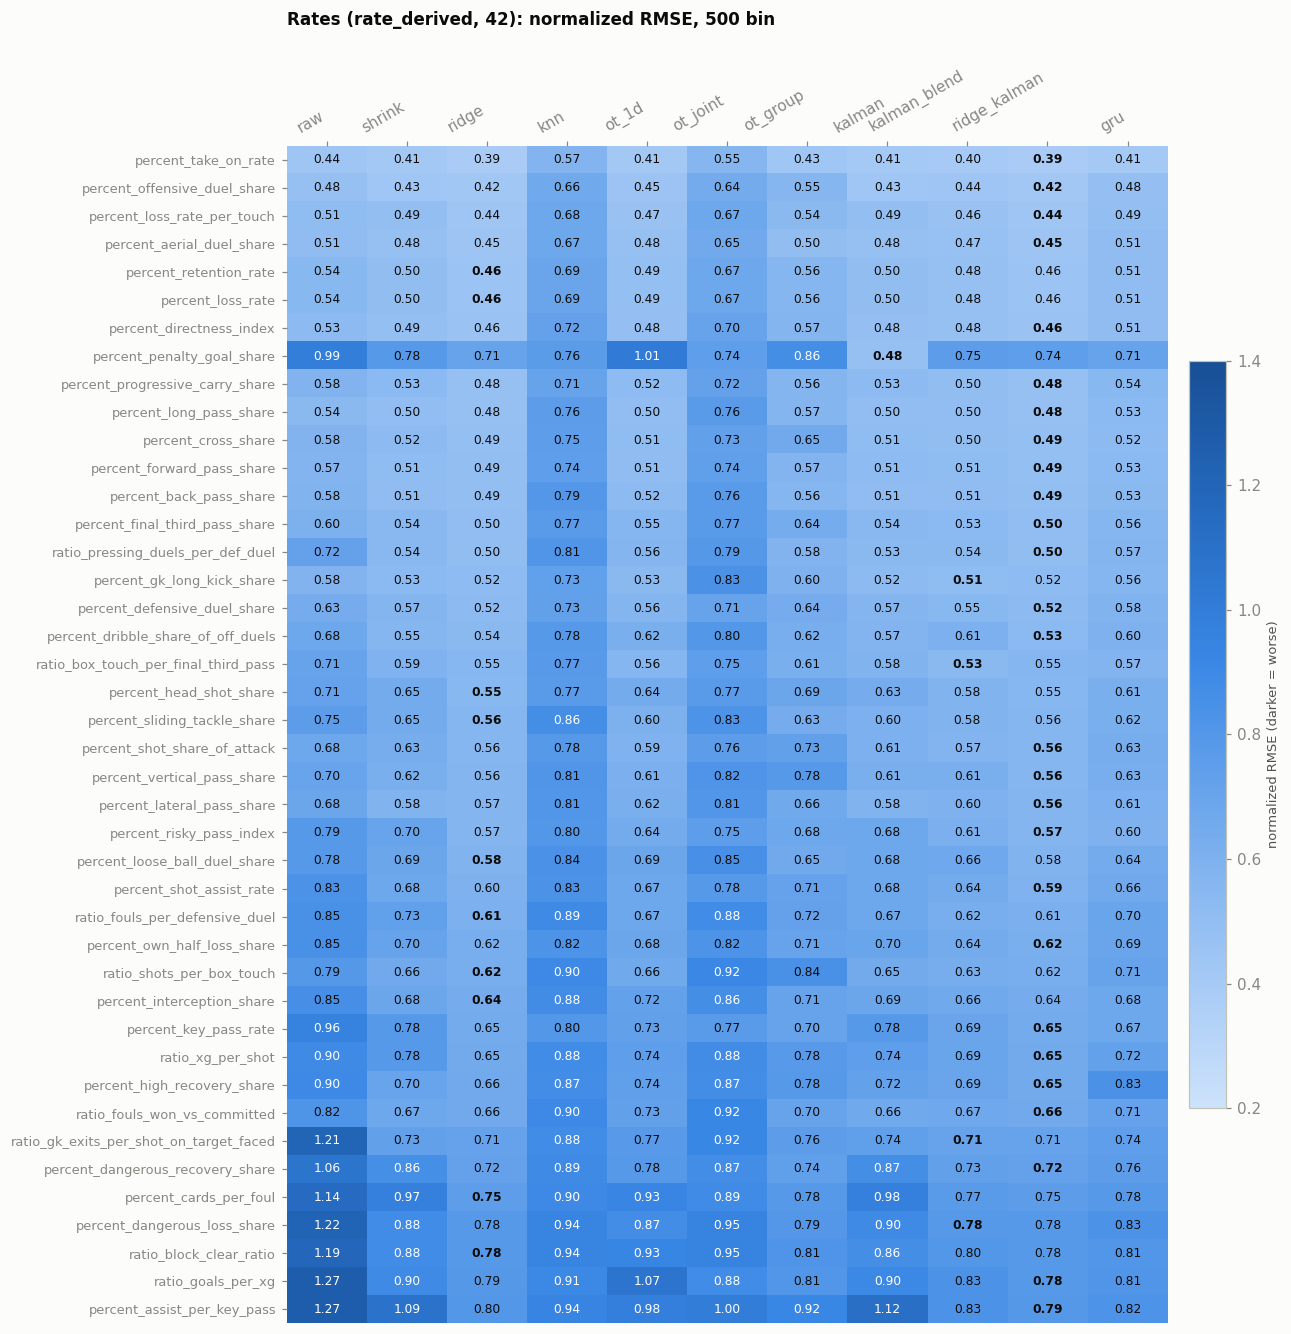

In [14]:
rt = nh.stat_table(R, ORDER, CP)
rbest = nh.best_per_stat(rt).dropna()
print(f"Best predicted rates, {CP} bin"); display(rbest.head(12).round(3))
print(f"Worst predicted rates, {CP} bin"); display(rbest.tail(12).iloc[::-1].round(3))
for st, sub in R.groupby("stat_type"):
    names = [n for n in sorted(sub["stat"].unique()) if n in rt.index]
    nh.heatmap(rt.loc[names], f"Rates ({st}, {len(names)}): normalized RMSE, {CP} bin")
    plt.show()

## 4. How we got here
The pipeline was built in stages and the earlier versions are kept only in `archive/`. Median normalized RMSE over volume stats at the 250 / 500 / 750 bins. **v1/v2 used fixed 250/500/750-minute checkpoint rows and v3 onwards uses minutes bins that contain every prefix, including very short ones, so v1/v2 numbers are not directly comparable with v3 onwards** (the raw baseline alone changes from 1.207 to 1.489 in the first bin).

| Version | What changed | Ridge | Other |
|---|---|---|---|
| v1 | separate model per checkpoint | 0.741 / 0.577 / 0.440 | shrink 0.806 / 0.646 / 0.523; KNN 0.850 / 0.768 / 0.709; best OT (group) 0.811 / 0.642 / 0.518; raw 1.207 / 0.749 / 0.504 |
| v2 | also train on per-match prefixes of the training players (windowed per checkpoint) | 0.743 / 0.578 / 0.441 | KNN improved ~0.017 at the two lower checkpoints; shrink and ridge unchanged |
| v3 | one model for any number of minutes, scored in 3 minute bins | 0.795 / 0.562 / 0.481 | shrink 0.817 / 0.618 / 0.524; raw 1.489 / 0.713 / 0.518 |
| v4 | z-score inputs against the distribution at that many minutes (**final ridge**) | 0.769 / 0.552 / 0.457 | trend features were worse than no trend; GRU and normalised OT did not beat the ridge; the Kalman estimate added a small gain (`ridge_kalman` 0.764 / 0.552 / 0.455) |

What mattered: the minutes-aware weight on the player's own value (`x * s(m)`, worth ~0.05) and z-scoring against the distribution at that many minutes (worth ~0.02-0.03). What did not: more training rows from the same seasons, recent-form trend features, a GRU, and normalising the OT source.

## 5. Caveats
- **Overlap with the truth.** The truth is the full-season per-90 and the low-minute sample is part of it. That flatters every method, and a regression most of all. A cleaner test scores against the *remaining* matches only.
- **Minutes bins.** The 250 bin averages prefixes from 0 to 375 minutes, so it is not the same sample as a fixed 250-minute checkpoint.
- **OT sample sizes.** The OT methods ran with capped row counts (`OT_FIT_ROWS`, `OT_REF_ROWS`); results may shift slightly with larger caps.
- **KNN is untuned** (K = 30), the GRU is one architecture and one seed, **GBM was not run** (too slow for ~100 targets across 14 groups).
- **`kalman_blend` assumption:** it uses the mean training full-season minutes as the divisor.
- **Truth set** is 900+ minutes only, so these errors describe players who went on to play a lot, who are not necessarily like players who stay at low minutes.
- Rebuilt percents are not clipped, so a few exceed 100. Rates with a tiny denominator are missing for some estimates; that is reported separately, not filled in.